In [1]:
import pickle
import pandas as pd

In [2]:
sub_id, trial_id, block_id = 0, 17, 2

In [3]:
with open(f"nba_results/trial{trial_id}/inner/inner_records.pkl", "rb") as f:
    inner_results = pickle.load(f)
with open(f"nba_results/trial{trial_id}/outer/outer_records.pkl", "rb") as f:
    outer_results = pickle.load(f)

print(inner_results[1])
print(outer_results[1])

{'outer_step': 0, 'inner_step': 1, 'aspiration': array([120.8,  38.1,  21.1,  13.5, 211.4]), 'obj_weight': array([0.25146019, 0.123183  , 0.25146019, 0.12243643, 0.25146019]), 'query_idx': 2555, 'query_pt': array([ 79.33186187,  37.0749766 ,  15.5344171 ,  14.18553053,
       154.45844279]), 'betas_weighted': array([-0.22536249, -0.32833944, -0.07778782, -0.01511179, -0.1124681 ]), 'obj_to_change_idx': 3, 'obj_to_change': 'BLK', 'change': 0.014479765590635966, 'target': array([ 79.33208504,  37.08574531,  15.53272545,  14.20001029,
       154.46102315]), 'new_query_idx': 2516, 'new_query_pt': array([ 79.17888781,  35.82203666,  15.18828344,  14.26180612,
       155.8267081 ])}
{'outer_step': 1, 'inner_step': 0, 'aspiration': array([ 79.33186187,  37.0749766 ,  15.5344171 ,  14.18553053,
       154.45844279]), 'obj_weight': array([0.20180448, 0.19814984, 0.20534491, 0.19643673, 0.19826405]), 'query_idx': 1831, 'query_pt': array([ 79.65783878,  36.55729166,  15.38196085,  14.4078896 ,
  

In [4]:
import ast

converters = {
    "initial_slider_values": ast.literal_eval,
    "slider_values": ast.literal_eval,
    "rec_values": ast.literal_eval,
}
all_info_nonshifted = pd.read_csv("../nba_game/data/all_info_10_nonshifted.csv", converters=converters)

subject_mapping = (
    all_info_nonshifted[["sub_id", "original_sub_id"]]
    .drop_duplicates()
    .sort_values("sub_id")
)
print(subject_mapping)

sub_id = 0
original_sub_id = int(
    subject_mapping.loc[subject_mapping["sub_id"] == sub_id, "original_sub_id"].iloc[0]
)

     sub_id  original_sub_id
0         0                2
84        1                3
121       2                4
173       3                5
236       4                6
300       5                8
369       6                9
447       7               10
517       8               11
572       9               12


In [5]:
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
from scipy.stats import percentileofscore, spearmanr

obj_names = ["REB", "AST", "STL", "BLK", "PTS"]

trial_rows = all_info_nonshifted.query("sub_id == @sub_id and trial_id == @trial_id") \
                                .sort_values("submission_number")
H_start = np.array(trial_rows.initial_slider_values.tolist())
H_ask = np.array(trial_rows.slider_values.tolist())
H_rec = np.array(trial_rows.rec_values.tolist())

outer_results = outer_results[:len(trial_rows)]
inner_results = inner_results[:len(trial_rows)]

A_ask = np.array([r["aspiration"] for r in outer_results])
A_rec = np.array([r["query_pt"] for r in outer_results])
A_start = np.vstack([H_start[:1], A_rec[:-1]])

I_ask = np.vstack([
    inner_results[0]["aspiration"],
    [r["query_pt"] for r in inner_results[1:]],
])
I_rec = np.array([r["query_pt"] for r in inner_results])

pf_path, = Path("../nba_game/data/game_data").glob(f"pf_block_{block_id}_trial_{trial_id}_*.csv")
pf_ref = pd.read_csv(pf_path).to_numpy()[:, :5]
iqr = np.subtract(*np.percentile(pf_ref, [75, 25], axis=0))

def to_pct(X):
    return np.array([[percentileofscore(pf_ref[:, j], x[j]) for j in range(5)] for x in X])

def to_weight(X):
    P = to_pct(X)
    return P / P.sum(1, keepdims=True)

def change_share(ask, start):
    d = (ask - start) / iqr
    s = np.abs(d).sum(1, keepdims=True)
    return np.divide(d, s, out=np.full_like(d, np.nan), where=s > 0)

H_w, A_w, I_w = to_weight(H_ask), to_weight(A_ask), to_weight(I_ask)
H_w_rec, A_w_rec, I_w_rec = to_weight(H_rec), to_weight(A_rec), to_weight(I_rec)
H_d, A_d = change_share(H_ask, H_start), change_share(A_ask, A_start)

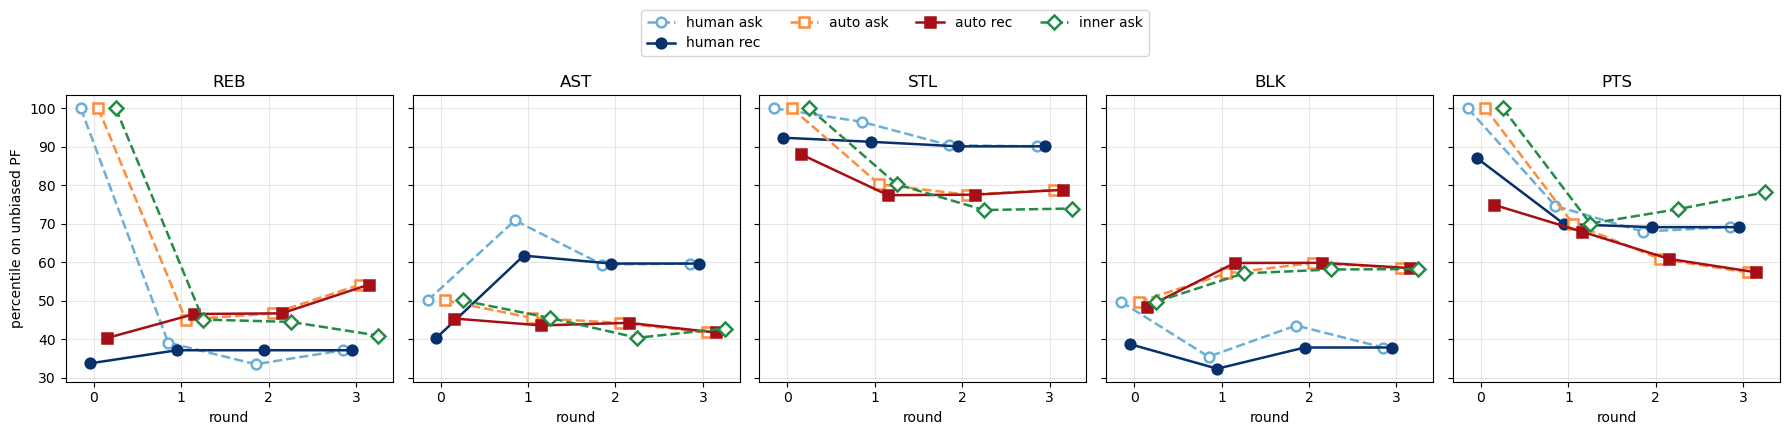

In [6]:
series = [
    (H_ask, "human ask",    dict(color="#6baed6", ls="--", marker="o", mfc="white"), -0.15),
    (H_rec, "human rec",       dict(color="#08306b", ls="-",  marker="o"),              -0.05),
    (A_ask, "auto ask", dict(color="#fd8d3c", ls="--", marker="s", mfc="white"),  0.05),
    (A_rec, "auto rec",   dict(color="#a50f15", ls="-",  marker="s"),               0.15),
    (I_ask, "inner ask", dict(color="#238b45", ls="--", marker="D", mfc="white"), 0.25),
]

fig, axes = plt.subplots(1, 5, figsize=(18, 3.8), sharey=True)
for j, ax in enumerate(axes):
    for X, label, style, dx in series:
        ax.plot(np.arange(len(X)) + dx, to_pct(X)[:, j], label=label, lw=1.8, ms=7, mew=1.8, **style)
    ax.set_title(obj_names[j]); ax.set_xlabel("round")
    ax.set_xticks(range(len(A_ask))); ax.grid(alpha=0.3)
axes[0].set_ylabel("percentile on unbiased PF")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.15))
fig.tight_layout()

In [ ]:
# ask
series = [
    (H_ask, "human aspi",    dict(color="#6baed6", ls="--", marker="o", mfc="white"), -0.15),
    (A_ask, "outer loop aspi", dict(color="#fd8d3c", ls="--", marker="s", mfc="white"),  0.05),
    (I_ask, "inner loop aspi", dict(color="#238b45", ls="--", marker="D", mfc="white"), 0.25),
]

fig, axes = plt.subplots(1, 5, figsize=(18, 3.8), sharey=True)
for j, ax in enumerate(axes):
    for X, label, style, dx in series:
        ax.plot(np.arange(len(X)) + dx, to_pct(X)[:, j], label=label, lw=1.8, ms=7, mew=1.8, **style)
    ax.set_title(obj_names[j]); ax.set_xlabel("round")
    ax.set_xticks(range(len(A_ask))); ax.grid(alpha=0.3)
axes[0].set_ylabel("percentile on unbiased PF")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.15))
fig.tight_layout()

In [ ]:
series = [
    (H_rec, "human rec",       dict(color="#08306b", ls="-",  marker="o"),              -0.05),
    (A_rec, "outer rec",   dict(color="#a50f15", ls="-",  marker="s"),               0.15),
    (I_rec, "inner rec", dict(color="#238b45", ls="--", marker="D"), 0.25),
]

fig, axes = plt.subplots(1, 5, figsize=(18, 3.8), sharey=True)
for j, ax in enumerate(axes):
    for X, label, style, dx in series:
        ax.plot(np.arange(len(X)) + dx, to_pct(X)[:, j], label=label, lw=1.8, ms=7, mew=1.8, **style)
    ax.set_title(obj_names[j]); ax.set_xlabel("round")
    ax.set_xticks(range(len(A_ask))); ax.grid(alpha=0.3)
axes[0].set_ylabel("percentile on unbiased PF")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.15))
fig.tight_layout()

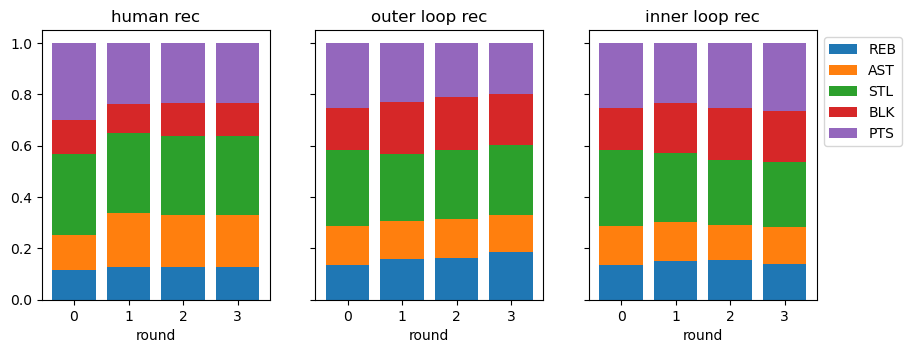

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), sharey=True)
for ax, W, title in [(axes[0], H_w_rec, "human rec"), (axes[1], A_w_rec, "outer loop rec"), (axes[2], I_w_rec, "inner loop rec")]:
    bottom = np.zeros(len(W))
    for j in range(5):
        ax.bar(range(len(W)), W[:, j], bottom=bottom, label=obj_names[j]); bottom += W[:, j]
    ax.set_title(title); ax.set_xlabel("round")
axes[-1].legend(bbox_to_anchor=(1, 1))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, D, title in [(axes[0], H_d, "human Δ share"), (axes[1], A_d, "auto Δ share")]:
    im = ax.imshow(D.T, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_yticks(range(5), obj_names); ax.set_xlabel("round"); ax.set_title(title)
fig.colorbar(im, ax=axes)

In [ ]:
n = min(len(H_d), len(A_d))
for k in range(n):
    cos = np.nansum(H_d[k] * A_d[k]) / (np.linalg.norm(np.nan_to_num(H_d[k])) * np.linalg.norm(np.nan_to_num(A_d[k])) + 1e-12)
    rho = spearmanr(H_w[k], A_w[k]).correlation
    print(f"round {k}: cos(Δ)={cos:.2f}  spearman(w)={rho:.2f}  L1(w)={np.abs(H_w[k]-A_w[k]).sum():.3f}")